# RetailPulse — Customer Churn Prediction

### Objective
Predict whether a customer will become inactive during a future prediction window,
using only information available during the historical observation period.

### Key Principles
- No future information in features
- Time-aware train/validation/test split
- Churn definition based on observed purchasing behavior
- Customer-level modeling
- Business-oriented churn risk scoring

In [2]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
sales_df = pd.read_parquet("../data/processed/clean_sales.parquet")
sales_df.head()

,invoice,stock_code,description,quantity,invoice_date,unit_price,customer_id,country,is_cancelled,revenue,description_clean
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom,False,83.4,15CM CHRISTMAS GLASS BALL 20 LIGHTS
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,False,81.0,PINK CHERRY LIGHTS
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,False,81.0,WHITE CHERRY LIGHTS
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom,False,100.8,"RECORD FRAME 7"" SINGLE SIZE"
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom,False,30.0,STRAWBERRY CERAMIC TRINKET BOX


In [4]:
sales_df.shape

(1007913, 11)

In [5]:
print("Column names:")
print(sales_df.columns.tolist())

print("\nData types:")
display(sales_df.dtypes)

print("\nDataset information:")
sales_df.info()

Column names:
['invoice', 'stock_code', 'description', 'quantity', 'invoice_date', 'unit_price', 'customer_id', 'country', 'is_cancelled', 'revenue', 'description_clean']

Data types:


invoice                      string
stock_code                   string
description                  string
quantity                      int64
invoice_date         datetime64[us]
unit_price                  float64
customer_id                   Int64
country                      string
is_cancelled                   bool
revenue                     float64
description_clean            string
dtype: object


Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 1007913 entries, 0 to 1007912
Data columns (total 11 columns):
 #   Column             Non-Null Count    Dtype         
---  ------             --------------    -----         
 0   invoice            1007913 non-null  string        
 1   stock_code         1007913 non-null  string        
 2   description        1007913 non-null  string        
 3   quantity           1007913 non-null  int64         
 4   invoice_date       1007913 non-null  datetime64[us]
 5   unit_price         1007913 non-null  float64       
 6   customer_id        779425 non-null   Int64         
 7   country            1007913 non-null  string        
 8   is_cancelled       1007913 non-null  bool          
 9   revenue            1007913 non-null  float64       
 10  description_clean  1007913 non-null  string        
dtypes: Int64(1), bool(1), datetime64[us](1), float64(2), int64(1), string(5)
memory usage: 153.7 MB


In [6]:
print("Missing values:")
display(sales_df.isna().sum().sort_values(ascending=False))

print("\nDuplicate rows:", sales_df.duplicated().sum())

print("\nUnique values:")
for col in sales_df.columns:
    print(f"{col}: {sales_df[col].nunique():,}")

Missing values:


customer_id          228488
invoice                   0
stock_code                0
description               0
quantity                  0
invoice_date              0
unit_price                0
country                   0
is_cancelled              0
revenue                   0
description_clean         0
dtype: int64


Duplicate rows: 0

Unique values:
invoice: 40,077
stock_code: 4,917
description: 5,399
quantity: 520
invoice_date: 37,212
unit_price: 2,275
customer_id: 5,878
country: 43
is_cancelled: 1
revenue: 7,099
description_clean: 5,399


In [7]:
date_candidates = []

for col in sales_df.columns:
    if pd.api.types.is_datetime64_any_dtype(sales_df[col]):
        date_candidates.append(col)

print("Datetime columns:")
print(date_candidates)

Datetime columns:
['invoice_date']


In [8]:
DATE_COL = "invoice_date"

print("Minimum date:", sales_df[DATE_COL].min())
print("Maximum date:", sales_df[DATE_COL].max())

print("\nDate range:")
print(sales_df[DATE_COL].max() - sales_df[DATE_COL].min())

Minimum date: 2009-12-01 07:45:00
Maximum date: 2011-12-09 12:50:00

Date range:
738 days 05:05:00


In [9]:
monthly_sales = (sales_df.set_index(DATE_COL).resample("MS").size())
display(monthly_sales)

invoice_date
2009-12-01    43453
2010-01-01    30317
2010-02-01    27952
2010-03-01    39841
2010-04-01    32858
2010-05-01    33383
2010-06-01    38391
2010-07-01    32112
2010-08-01    32109
2010-09-01    40630
2010-10-01    56953
2010-11-01    75035
2010-12-01    40991
2011-01-01    34060
2011-02-01    26882
2011-03-01    35497
2011-04-01    28882
2011-05-01    35917
2011-06-01    35716
2011-07-01    38395
2011-08-01    34264
2011-09-01    48900
2011-10-01    58537
2011-11-01    82004
2011-12-01    24834
Freq: MS, dtype: int64

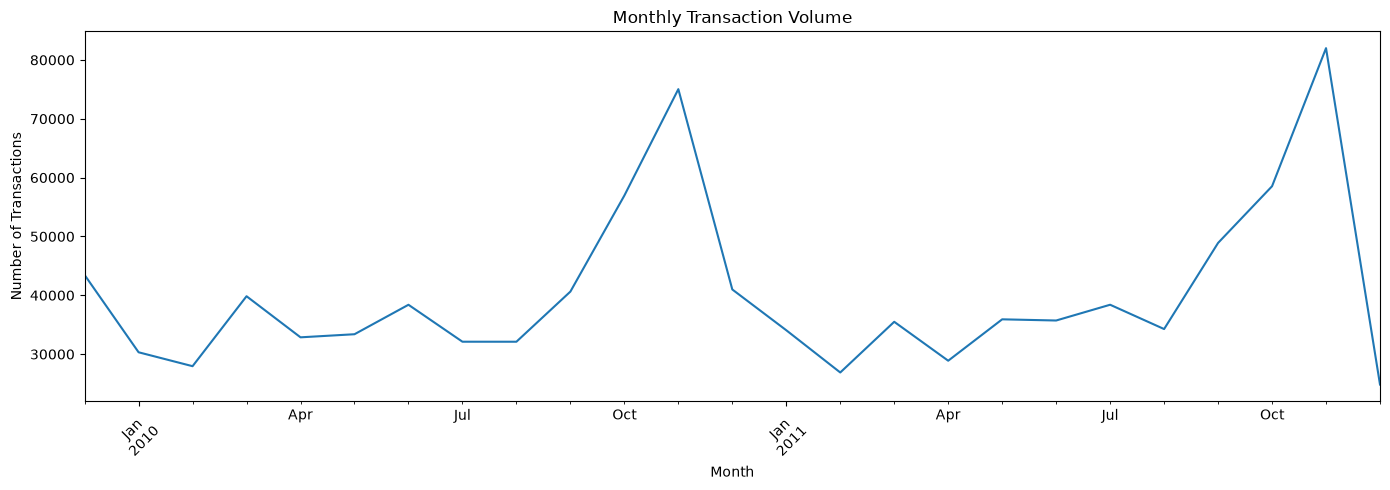

In [10]:
plt.figure(figsize=(14, 5))

monthly_sales.plot()

plt.title("Monthly Transaction Volume")
plt.xlabel("Month")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [11]:
# Basic cancellation analysis

print("Cancellation flag distribution:")
display(sales_df["is_cancelled"].value_counts(dropna=False).rename_axis("is_cancelled").to_frame("row_count"))

print("\nCancellation percentage:")
display((sales_df["is_cancelled"].value_counts(normalize=True, dropna=False) * 100).rename("percentage"))

print("\nInvoice count by cancellation status:")

invoice_cancellation = (sales_df.groupby("is_cancelled").agg(unique_invoices=("invoice", "nunique"),unique_customers=("customer_id", "nunique"),total_rows=("invoice", "size"),total_revenue=("revenue", "sum")))

display(invoice_cancellation)

Cancellation flag distribution:


,row_count
is_cancelled,
False,1007913



Cancellation percentage:


is_cancelled
False    100.0
Name: percentage, dtype: float64


Invoice count by cancellation status:


,unique_invoices,unique_customers,total_rows,total_revenue
is_cancelled,,,,
False,40077,5878,1007913,2.047626e+07


In [12]:
# Check whether an invoice has multiple cancellation statuses

invoice_status_counts = (sales_df.groupby("invoice")["is_cancelled"].nunique()
)

mixed_status_invoices = invoice_status_counts[invoice_status_counts > 1]

print("Invoices with inconsistent cancellation status:",len(mixed_status_invoices))

print("Total unique invoices:",sales_df["invoice"].nunique())

if len(mixed_status_invoices) > 0:
    print("\nSample inconsistent invoices:")
    display(sales_df[sales_df["invoice"].isin(mixed_status_invoices.index)].sort_values(["invoice", "invoice_date"]).head(20))

Invoices with inconsistent cancellation status: 0
Total unique invoices: 40077


In [13]:
# Preliminary eligible purchase rows

purchase_rows = sales_df.loc[sales_df["customer_id"].notna()& (~sales_df["is_cancelled"])& sales_df["invoice"].notna()& sales_df["invoice_date"].notna()].copy()

print("Original rows:", len(sales_df))
print("Preliminary purchase rows:", len(purchase_rows))

print("Customers:",purchase_rows["customer_id"].nunique())

print("Invoices:",purchase_rows["invoice"].nunique())

print("Date range:",purchase_rows["invoice_date"].min(),"to",purchase_rows["invoice_date"].max())

Original rows: 1007913
Preliminary purchase rows: 779425
Customers: 5878
Invoices: 36969
Date range: 2009-12-01 07:45:00 to 2011-12-09 12:50:00


In [14]:
# Aggregate product rows into customer-level invoices

invoice_level = (purchase_rows.groupby(["customer_id", "invoice"], as_index=False).agg(
        invoice_date=("invoice_date", "min"),
        invoice_revenue=("revenue", "sum"),
        total_quantity=("quantity", "sum"),
        unique_products=("stock_code", "nunique"),
        invoice_rows=("stock_code", "size")
    )
)

print("Invoice-level dataset shape:", invoice_level.shape)

display(invoice_level.head())

print("\nInvoice-level summary:")
display(invoice_level[["invoice_revenue","total_quantity","unique_products","invoice_rows"]].describe())

Invoice-level dataset shape: (36969, 7)


,customer_id,invoice,invoice_date,invoice_revenue,total_quantity,unique_products,invoice_rows
0,12346,491725,2009-12-14 08:34:00,45.0,10,1,1
1,12346,491742,2009-12-14 11:00:00,22.5,5,1,1
2,12346,491744,2009-12-14 11:02:00,22.5,5,1,1
3,12346,492718,2009-12-18 10:47:00,22.5,5,1,1
4,12346,492722,2009-12-18 10:55:00,1.0,1,1,1



Invoice-level summary:


,invoice_revenue,total_quantity,unique_products,invoice_rows
count,36969.000000,36969.000000,36969.000000,36969.0
mean,469.983074,284.399145,20.797560,21.083205
std,1359.741927,1232.382259,22.399873,22.964763
min,0.380000,1.000000,1.000000,1.0
25%,157.920000,72.000000,6.000000,6.0
50%,303.040000,151.000000,15.000000,15.0
75%,477.280000,287.000000,27.000000,27.0
max,168469.600000,87167.000000,541.000000,542.0


In [15]:
customer_purchase_counts = (invoice_level.groupby("customer_id").agg(
        purchase_count=("invoice", "nunique"),
        first_purchase=("invoice_date", "min"),
        last_purchase=("invoice_date", "max"),
        total_revenue=("invoice_revenue", "sum"),
        total_quantity=("total_quantity", "sum")
    )
)

print("Customer summary shape:", customer_purchase_counts.shape)

display(customer_purchase_counts[["purchase_count","total_revenue","total_quantity"]].describe())

Customer summary shape: (5878, 5)


,purchase_count,total_revenue,total_quantity
count,5878.000000,5878.000000,5878.000000
mean,6.289384,2955.904095,1788.695475
std,13.009406,14440.852688,8876.297196
min,1.000000,2.950000,1.000000
25%,1.000000,342.280000,187.000000
50%,3.000000,867.740000,480.000000
75%,7.000000,2248.305000,1350.000000
max,398.000000,580987.040000,367193.000000


In [16]:
# Purchase frequency distribution

purchase_frequency_distribution = (customer_purchase_counts["purchase_count"].value_counts().sort_index())

display(purchase_frequency_distribution.head(20))

print("\nCustomers with only one observed purchase:")
print((customer_purchase_counts["purchase_count"] == 1).sum())

print("\nCustomers with at least two observed purchases:")
print((customer_purchase_counts["purchase_count"] >= 2).sum())

print("\nCustomers with at least five observed purchases:")
print((customer_purchase_counts["purchase_count"] >= 5).sum())

purchase_count
1     1623
2      944
3      664
4      486
5      360
6      280
7      222
8      172
9      153
10      98
11     131
12      96
13      79
14      49
15      51
16      43
17      41
18      32
19      26
20      31
Name: count, dtype: int64


Customers with only one observed purchase:
1623

Customers with at least two observed purchases:
4255

Customers with at least five observed purchases:
2161


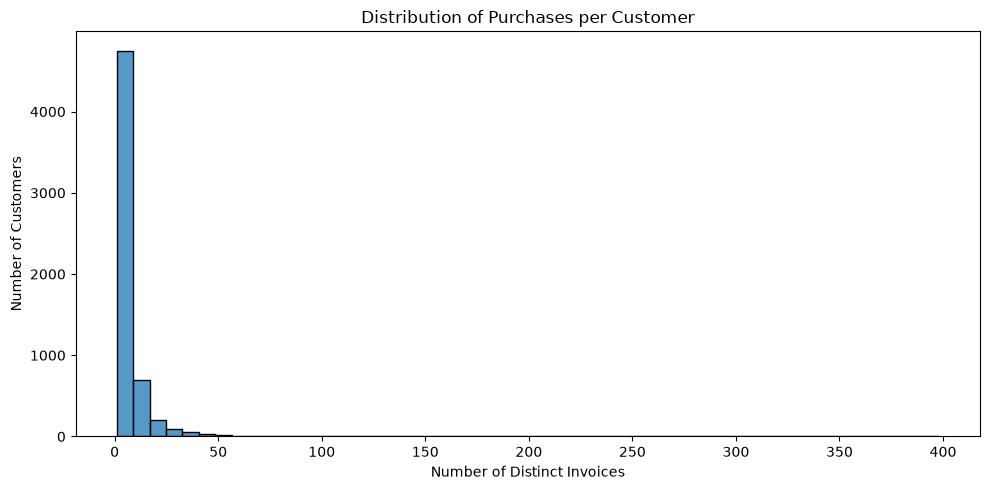

In [17]:
plt.figure(figsize=(10, 5))

sns.histplot(data=customer_purchase_counts,x="purchase_count",bins=50)

plt.title("Distribution of Purchases per Customer")
plt.xlabel("Number of Distinct Invoices")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

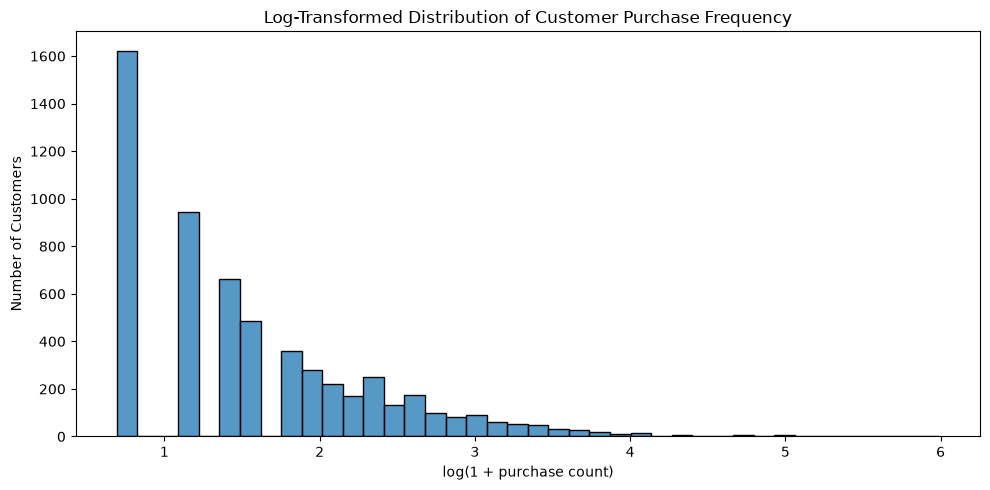

In [18]:
plt.figure(figsize=(10, 5))

sns.histplot(np.log1p(customer_purchase_counts["purchase_count"]),bins=40)

plt.title("Log-Transformed Distribution of Customer Purchase Frequency")
plt.xlabel("log(1 + purchase count)")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

In [19]:
# Sort invoices chronologically

invoice_level = invoice_level.sort_values(["customer_id", "invoice_date", "invoice"]).reset_index(drop=True)

# Days between consecutive invoices for each customer

invoice_level["days_since_previous_purchase"] = (invoice_level.groupby("customer_id")["invoice_date"].diff().dt.total_seconds().div(86400))

interpurchase_intervals = invoice_level.loc[invoice_level["days_since_previous_purchase"].notna(),
    [
        "customer_id",
        "invoice",
        "invoice_date",
        "days_since_previous_purchase"
    ]
].copy()

print("Number of observed interpurchase intervals:",len(interpurchase_intervals))

display(interpurchase_intervals["days_since_previous_purchase"].describe(percentiles=[0.10, 0.25, 0.50, 0.75, 0.90, 0.95]))

Number of observed interpurchase intervals: 31091


count    31091.000000
mean        51.686656
std         75.788911
min          0.000000
10%          0.013194
25%          6.983333
50%         24.743056
75%         61.810417
90%        134.875694
95%        206.426736
max        714.152083
Name: days_since_previous_purchase, dtype: float64

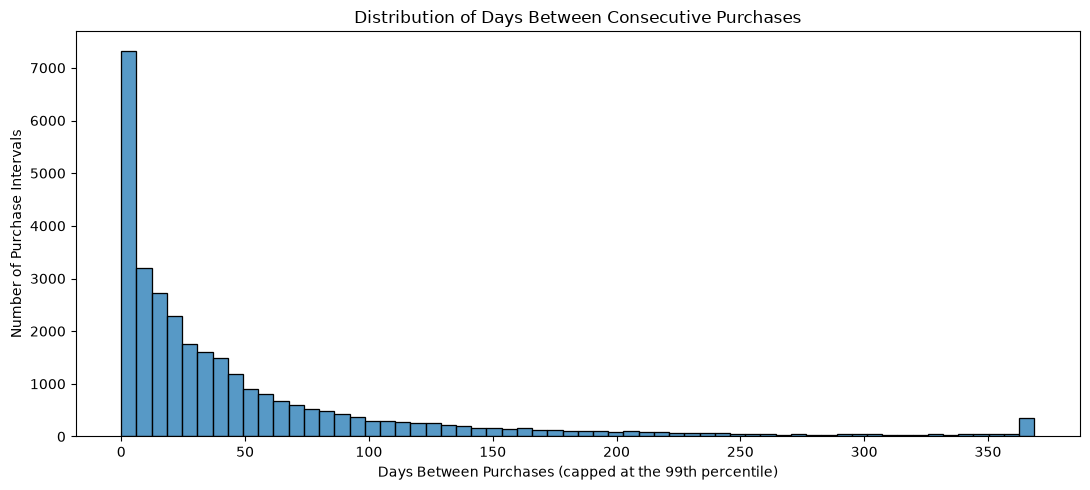

In [20]:
intervals = interpurchase_intervals["days_since_previous_purchase"]

plt.figure(figsize=(11, 5))

sns.histplot(intervals.clip(upper=intervals.quantile(0.99)),bins=60)

plt.title("Distribution of Days Between Consecutive Purchases")
plt.xlabel("Days Between Purchases (capped at the 99th percentile)")
plt.ylabel("Number of Purchase Intervals")
plt.tight_layout()
plt.show()

In [21]:
interval_percentiles = (interpurchase_intervals["days_since_previous_purchase"]
    .quantile([0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99])
    .rename_axis("percentile")
    .to_frame("days_between_purchases")
)

display(interval_percentiles)

,days_between_purchases
percentile,
0.10,0.013194
0.25,6.983333
0.50,24.743056
0.75,61.810417
0.90,134.875694
0.95,206.426736
0.99,368.740764


In [22]:
customer_cadence = (interpurchase_intervals.groupby("customer_id").agg(
        observed_intervals=("days_since_previous_purchase","size"),
        median_days_between_purchases=("days_since_previous_purchase","median"),
        mean_days_between_purchases=("days_since_previous_purchase","mean"),
        p90_days_between_purchases=("days_since_previous_purchase",lambda x: x.quantile(0.90))
    )
)

display(customer_cadence[
        [
            "observed_intervals",
            "median_days_between_purchases",
            "mean_days_between_purchases",
            "p90_days_between_purchases"
        ]
    ].describe()
)

,observed_intervals,median_days_between_purchases,mean_days_between_purchases,p90_days_between_purchases
count,4255.000000,4255.000000,4255.000000,4255.000000
mean,7.306933,92.714992,102.300645,148.314149
std,14.801008,101.177919,98.277152,113.272025
min,1.000000,0.000000,0.000000,0.000000
25%,2.000000,28.079861,38.576845,62.631806
50%,4.000000,55.972222,72.335880,121.904167
75%,8.000000,118.185764,129.843750,204.801111
max,397.000000,714.152083,714.152083,714.152083


In [23]:
monthly_customer_activity = (invoice_level.assign(month=lambda df: (df["invoice_date"].dt.to_period("M"))).groupby("month")
    .agg(
        unique_customers=("customer_id", "nunique"),
        unique_invoices=("invoice", "nunique"),
        total_revenue=("invoice_revenue", "sum")
    )
)

display(monthly_customer_activity)

,unique_customers,unique_invoices,total_revenue
month,,,
2009-12,955,1512,683504.010
2010-01,720,1011,555802.672
2010-02,772,1104,504558.956
2010-03,1057,1524,696978.471
2010-04,942,1329,591982.002
2010-05,966,1377,597833.380
2010-06,1041,1497,636371.130
2010-07,928,1381,589736.170
2010-08,911,1293,602224.600


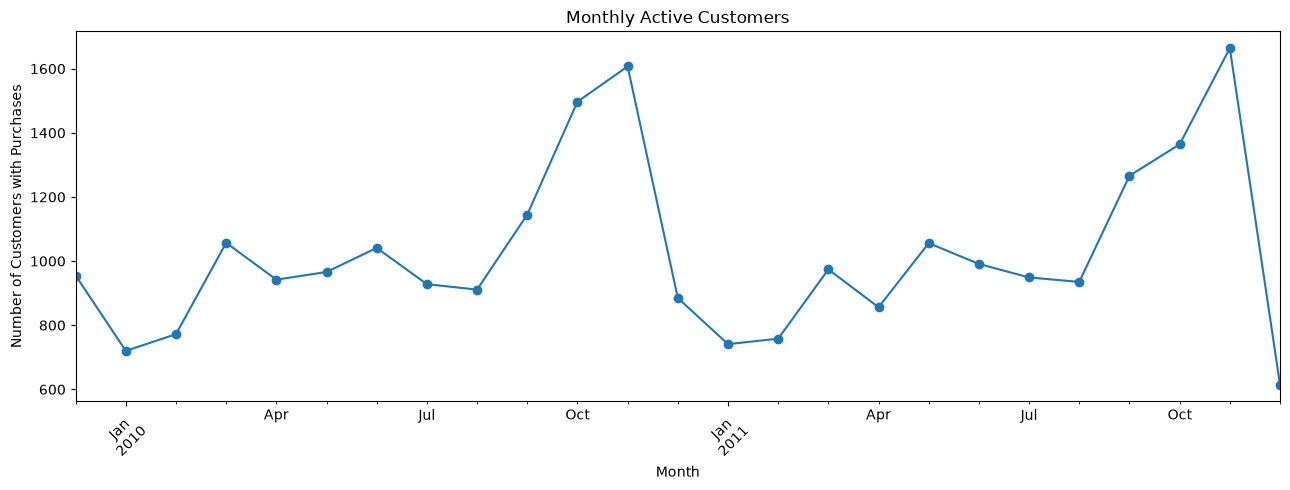

In [24]:
plt.figure(figsize=(13, 5))

monthly_customer_activity["unique_customers"].plot(marker="o")

plt.title("Monthly Active Customers")
plt.xlabel("Month")
plt.ylabel("Number of Customers with Purchases")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

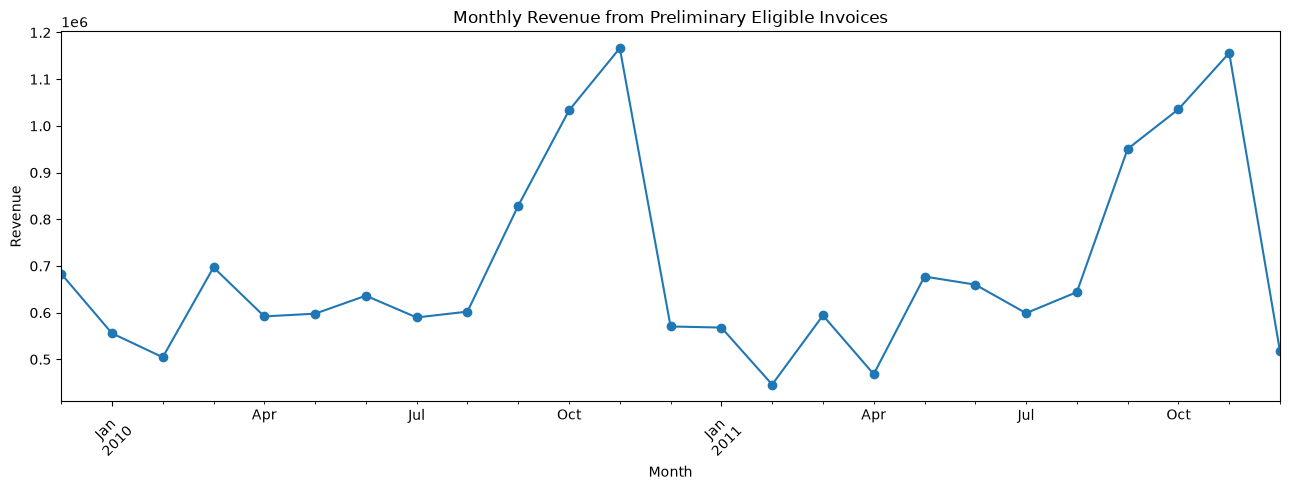

In [25]:
plt.figure(figsize=(13, 5))

monthly_customer_activity["total_revenue"].plot(marker="o")

plt.title("Monthly Revenue from Preliminary Eligible Invoices")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [26]:
# Inspect quantities and revenue in the original dataset

print("Quantity distribution:")
display(sales_df["quantity"].describe(percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]))

print("\nRevenue distribution:")
display(sales_df["revenue"].describe(percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]))

print("\nNegative quantity rows:")
print((sales_df["quantity"] < 0).sum())

print("\nZero quantity rows:")
print((sales_df["quantity"] == 0).sum())

print("\nNegative revenue rows:")
print((sales_df["revenue"] < 0).sum())

print("\nZero revenue rows:")
print((sales_df["revenue"] == 0).sum())

Quantity distribution:


count    1.007913e+06
mean     1.111718e+01
std      1.284700e+02
min      1.000000e+00
1%       1.000000e+00
5%       1.000000e+00
25%      1.000000e+00
50%      4.000000e+00
75%      1.200000e+01
95%      3.100000e+01
99%      1.080000e+02
max      8.099500e+04
Name: quantity, dtype: float64


Revenue distribution:


count    1.007913e+06
mean     2.031550e+01
std      2.057158e+02
min      1.000000e-03
1%       6.500000e-01
5%       1.250000e+00
25%      4.130000e+00
50%      1.008000e+01
75%      1.770000e+01
95%      6.000000e+01
99%      1.845880e+02
max      1.684696e+05
Name: revenue, dtype: float64


Negative quantity rows:
0

Zero quantity rows:
0

Negative revenue rows:
0

Zero revenue rows:
0


In [27]:
returns_df = pd.read_parquet("../data/processed/clean_returns.parquet")
cancelled_df = pd.read_parquet("../data/processed/clean_cancelled.parquet")

print("Returns dataset")
print("Shape:", returns_df.shape)
print("Columns:", returns_df.columns.tolist())
display(returns_df.head())

print("\nCancelled dataset")
print("Shape:", cancelled_df.shape)
print("Columns:", cancelled_df.columns.tolist())
display(cancelled_df.head())

Returns dataset
Shape: (22496, 11)
Columns: ['invoice', 'stock_code', 'description', 'quantity', 'invoice_date', 'unit_price', 'customer_id', 'country', 'is_cancelled', 'revenue', 'description_clean']


,invoice,stock_code,description,quantity,invoice_date,unit_price,customer_id,country,is_cancelled,revenue,description_clean
0,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01 10:33:00,2.95,16321,Australia,True,-35.4,PAPER BUNTING WHITE LACE
1,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01 10:33:00,1.65,16321,Australia,True,-9.9,CREAM FELT EASTER EGG BASKET
2,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,2009-12-01 10:33:00,4.25,16321,Australia,True,-17.0,POTTING SHED SOW 'N' GROW SET
3,C489449,21896,POTTING SHED TWINE,-6,2009-12-01 10:33:00,2.10,16321,Australia,True,-12.6,POTTING SHED TWINE
4,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2009-12-01 10:33:00,2.95,16321,Australia,True,-35.4,PAPER CHAIN KIT RETRO SPOT



Cancelled dataset
Shape: (19104, 11)
Columns: ['invoice', 'stock_code', 'description', 'quantity', 'invoice_date', 'unit_price', 'customer_id', 'country', 'is_cancelled', 'revenue', 'description_clean']


,invoice,stock_code,description,quantity,invoice_date,unit_price,customer_id,country,is_cancelled,revenue,description_clean
0,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01 10:33:00,2.95,16321,Australia,True,-35.4,PAPER BUNTING WHITE LACE
1,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01 10:33:00,1.65,16321,Australia,True,-9.9,CREAM FELT EASTER EGG BASKET
2,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,2009-12-01 10:33:00,4.25,16321,Australia,True,-17.0,POTTING SHED SOW 'N' GROW SET
3,C489449,21896,POTTING SHED TWINE,-6,2009-12-01 10:33:00,2.10,16321,Australia,True,-12.6,POTTING SHED TWINE
4,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2009-12-01 10:33:00,2.95,16321,Australia,True,-35.4,PAPER CHAIN KIT RETRO SPOT


In [28]:
print("Returns data types:")
display(returns_df.dtypes)

print("\nCancelled data types:")
display(cancelled_df.dtypes)

Returns data types:


invoice                      string
stock_code                   string
description                  string
quantity                      int64
invoice_date         datetime64[us]
unit_price                  float64
customer_id                   Int64
country                      string
is_cancelled                   bool
revenue                     float64
description_clean            string
dtype: object


Cancelled data types:


invoice                      string
stock_code                   string
description                  string
quantity                      int64
invoice_date         datetime64[us]
unit_price                  float64
customer_id                   Int64
country                      string
is_cancelled                   bool
revenue                     float64
description_clean            string
dtype: object

In [29]:
# Time coverage of identified-customer transactions

identified_sales = sales_df.loc[sales_df["customer_id"].notna()].copy()

data_start = identified_sales["invoice_date"].min()
data_end = identified_sales["invoice_date"].max()

print("Data start:", data_start)
print("Data end:", data_end)

print("Total available days:",(data_end - data_start).days)

print("Available months:",(data_end.year - data_start.year) * 12 + data_end.month - data_start.month + 1)

Data start: 2009-12-01 07:45:00
Data end: 2011-12-09 12:50:00
Total available days: 738
Available months: 25


In [30]:
# RetailPulse: dataset consistency checks

datasets = {
    "sales": sales_df,
    "returns": returns_df,
    "cancelled": cancelled_df
}

for name, df in datasets.items():
    print(f"\n{'=' * 60}")
    print(f"Dataset: {name}")
    print(f"{'=' * 60}")

    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())

    print("Unique invoices:",df["invoice"].nunique())

    print("Unique customers:",df["customer_id"].nunique())

    print("Date range:",df["invoice_date"].min(),"to",df["invoice_date"].max())

    print("Cancellation values:",df["is_cancelled"].value_counts(dropna=False).to_dict())

    print("Negative quantities:",(df["quantity"] < 0).sum())

    print("Negative revenues:",(df["revenue"] < 0).sum())


Dataset: sales
Shape: (1007913, 11)
Columns: ['invoice', 'stock_code', 'description', 'quantity', 'invoice_date', 'unit_price', 'customer_id', 'country', 'is_cancelled', 'revenue', 'description_clean']
Unique invoices: 40077
Unique customers: 5878
Date range: 2009-12-01 07:45:00 to 2011-12-09 12:50:00
Cancellation values: {False: 1007913}
Negative quantities: 0
Negative revenues: 0

Dataset: returns
Shape: (22496, 11)
Columns: ['invoice', 'stock_code', 'description', 'quantity', 'invoice_date', 'unit_price', 'customer_id', 'country', 'is_cancelled', 'revenue', 'description_clean']
Unique invoices: 11684
Unique customers: 2572
Date range: 2009-12-01 10:33:00 to 2011-12-09 11:58:00
Cancellation values: {True: 19103, False: 3393}
Negative quantities: 22496
Negative revenues: 19103

Dataset: cancelled
Shape: (19104, 11)
Columns: ['invoice', 'stock_code', 'description', 'quantity', 'invoice_date', 'unit_price', 'customer_id', 'country', 'is_cancelled', 'revenue', 'description_clean']
Uniqu

In [31]:
# Compare invoice identifiers across datasets

sales_invoices = set(sales_df["invoice"].dropna().unique())
returns_invoices = set(returns_df["invoice"].dropna().unique())
cancelled_invoices = set(cancelled_df["invoice"].dropna().unique())

print("Sales invoices:", len(sales_invoices))
print("Return invoices:", len(returns_invoices))
print("Cancelled invoices:", len(cancelled_invoices))

print("\nSales-return invoice overlap:",len(sales_invoices & returns_invoices))

print("Sales-cancelled invoice overlap:",len(sales_invoices & cancelled_invoices))

print("Return-cancelled invoice overlap:",len(returns_invoices & cancelled_invoices))

print("Invoices appearing in all three datasets:",len(sales_invoices & returns_invoices & cancelled_invoices))

Sales invoices: 40077
Return invoices: 11684
Cancelled invoices: 8292

Sales-return invoice overlap: 0
Sales-cancelled invoice overlap: 0
Return-cancelled invoice overlap: 8291
Invoices appearing in all three datasets: 0


In [32]:
print("Sales cancellation flag:")
display(sales_df["is_cancelled"].value_counts(dropna=False))

print("\nReturns cancellation flag:")
display(returns_df["is_cancelled"].value_counts(dropna=False))

print("\nCancelled dataset cancellation flag:")
display(cancelled_df["is_cancelled"].value_counts(dropna=False))

Sales cancellation flag:


is_cancelled
False    1007913
Name: count, dtype: int64


Returns cancellation flag:


is_cancelled
True     19103
False     3393
Name: count, dtype: int64


Cancelled dataset cancellation flag:


is_cancelled
True    19104
Name: count, dtype: int64

In [33]:
# Inspect monthly coverage using identified customers

identified_sales = sales_df.loc[sales_df["customer_id"].notna()].copy()

monthly_coverage = (identified_sales.assign(month=identified_sales["invoice_date"].dt.to_period("M")).groupby("month").agg(
        rows=("invoice", "size"),
        invoices=("invoice", "nunique"),
        customers=("customer_id", "nunique"),
        revenue=("revenue", "sum")
    )
)

display(monthly_coverage)

,rows,invoices,customers,revenue
month,,,,
2009-12,30272,1512,955,683504.010
2010-01,21458,1011,720,555802.672
2010-02,23040,1104,772,504558.956
2010-03,31782,1524,1057,696978.471
2010-04,26831,1329,942,591982.002
2010-05,28233,1377,966,597833.380
2010-06,30688,1497,1041,636371.130
2010-07,26643,1381,928,589736.170
2010-08,26029,1293,911,602224.600


In [34]:
# Candidate historical observation cutoffs

data_start = identified_sales["invoice_date"].min()
data_end = identified_sales["invoice_date"].max()

feature_days = 180
candidate_horizons = [90, 120, 150]

# Generate monthly cutoffs beginning after sufficient feature history.
# Cutoffs are placed at midnight on the first day of each month.

first_cutoff = (data_start.normalize()+ pd.Timedelta(days=feature_days)).to_period("M").start_time

last_cutoff = data_end.normalize()

candidate_cutoffs = pd.date_range(start=first_cutoff,end=last_cutoff,freq="MS")

cutoff_summary = []

for cutoff in candidate_cutoffs:
    row = {
        "observation_cutoff": cutoff,
        "feature_start": cutoff - pd.Timedelta(days=feature_days),
        "days_remaining_after_cutoff": (data_end - cutoff).days
    }

    for horizon in candidate_horizons:
        row[f"supports_{horizon}d_horizon"] = (cutoff + pd.Timedelta(days=horizon) <= data_end)

    cutoff_summary.append(row)

cutoff_summary = pd.DataFrame(cutoff_summary)

display(cutoff_summary)

,observation_cutoff,feature_start,days_remaining_after_cutoff,supports_90d_horizon,supports_120d_horizon,supports_150d_horizon
0,2010-05-01,2009-11-02,587,True,True,True
1,2010-06-01,2009-12-03,556,True,True,True
2,2010-07-01,2010-01-02,526,True,True,True
3,2010-08-01,2010-02-02,495,True,True,True
4,2010-09-01,2010-03-05,464,True,True,True
5,2010-10-01,2010-04-04,434,True,True,True
6,2010-11-01,2010-05-05,403,True,True,True
7,2010-12-01,2010-06-04,373,True,True,True
8,2011-01-01,2010-07-05,342,True,True,True
9,2011-02-01,2010-08-05,311,True,True,True


In [35]:
# Identify invoice IDs unique to each dataset
returns_invoice_ids = set(returns_df["invoice"].dropna().unique())

cancelled_invoice_ids = set(cancelled_df["invoice"].dropna().unique())

returns_only = returns_invoice_ids - cancelled_invoice_ids
cancelled_only = cancelled_invoice_ids - returns_invoice_ids
shared_invoices = returns_invoice_ids & cancelled_invoice_ids

print("Invoices in returns:", len(returns_invoice_ids))
print("Invoices in cancellations:", len(cancelled_invoice_ids))
print("Shared invoices:", len(shared_invoices))

print("\nInvoices only in returns:", len(returns_only))
print("Invoices only in cancellations:", len(cancelled_only))

print("\nSample return-only invoices:")
print(list(returns_only)[:20])

print("\nSample cancellation-only invoices:")
print(list(cancelled_only)[:20])

Invoices in returns: 11684
Invoices in cancellations: 8292
Shared invoices: 8291

Invoices only in returns: 3393
Invoices only in cancellations: 1

Sample return-only invoices:
['508860', '530876', '508022', '540638', '559314', '496991', '581204', '529542', '507803', '499373', '498870', '558464', '558309', '499822', '531140', '497361', '538837', '507884', '496909', '495212']

Sample cancellation-only invoices:
['C496350']


In [36]:
# Select a few invoices that occur in both datasets

sample_shared_invoices = list(shared_invoices)[:5]

comparison_columns = ["invoice","stock_code","quantity","invoice_date","customer_id","is_cancelled","revenue"]

print("RETURN DATASET")

display(returns_df.loc[returns_df["invoice"].isin(sample_shared_invoices),comparison_columns].sort_values(["invoice", "stock_code"]))

print("\nCANCELLED DATASET")

display(cancelled_df.loc[cancelled_df["invoice"].isin(sample_shared_invoices),comparison_columns].sort_values(["invoice", "stock_code"]))

RETURN DATASET


,invoice,stock_code,quantity,invoice_date,customer_id,is_cancelled,revenue
462,C490980,21890,-4,2009-12-08 16:55:00,15194,True,-11.80
461,C490980,22319,-1,2009-12-08 16:55:00,15194,True,-0.65
463,C490980,85048,-2,2009-12-08 16:55:00,15194,True,-13.90
857,C492400,85147,-2,2009-12-16 15:38:00,14540,True,-9.90
9307,C524636,21314,-2,2010-09-30 11:27:00,14226,True,-4.20
13025,C541234,22441,-1,2011-01-14 17:11:00,13862,True,-2.10
13026,C541234,22960,-2,2011-01-14 17:11:00,13862,True,-7.50
17126,C558471,22974,-1,2011-06-29 15:38:00,12408,True,-1.65



CANCELLED DATASET


,invoice,stock_code,quantity,invoice_date,customer_id,is_cancelled,revenue
431,C490980,21890,-4,2009-12-08 16:55:00,15194,True,-11.80
430,C490980,22319,-1,2009-12-08 16:55:00,15194,True,-0.65
432,C490980,85048,-2,2009-12-08 16:55:00,15194,True,-13.90
789,C492400,85147,-2,2009-12-16 15:38:00,14540,True,-9.90
7595,C524636,21314,-2,2010-09-30 11:27:00,14226,True,-4.20
10868,C541234,22441,-1,2011-01-14 17:11:00,13862,True,-2.10
10869,C541234,22960,-2,2011-01-14 17:11:00,13862,True,-7.50
14315,C558471,22974,-1,2011-06-29 15:38:00,12408,True,-1.65


In [ ]:
# Summarize return records by cancellation status

returns_status_summary = (returns_df.groupby("is_cancelled", dropna=False).agg(
        rows=("invoice", "size"),
        invoices=("invoice", "nunique"),
        customers=("customer_id", "nunique"),
        quantity=("quantity", "sum"),
        revenue=("revenue", "sum")
    )
)

display(returns_status_summary)

,rows,invoices,customers,quantity,revenue
is_cancelled,,,,,
False,3393,3393,0,-569314,0.00
True,19103,8291,2572,-476820,-1462424.18


In [38]:
# Inspect return-dataset records not marked as cancelled

non_cancelled_returns = returns_df.loc[returns_df["is_cancelled"].eq(False)].copy()

print("Rows:", len(non_cancelled_returns))
print("Unique invoices:", non_cancelled_returns["invoice"].nunique())
print("Unique customers:", non_cancelled_returns["customer_id"].nunique())

display(non_cancelled_returns.head(10))

Rows: 3393
Unique invoices: 3393
Unique customers: 0


,invoice,stock_code,description,quantity,invoice_date,unit_price,customer_id,country,is_cancelled,revenue,description_clean
22,489464,21733,85123a mixed,-96,2009-12-01 10:52:00,0.0,<NA>,United Kingdom,False,-0.0,85123a mixed
23,489463,71477,short,-240,2009-12-01 10:52:00,0.0,<NA>,United Kingdom,False,-0.0,short
24,489467,85123A,21733 mixed,-192,2009-12-01 10:53:00,0.0,<NA>,United Kingdom,False,-0.0,21733 mixed
32,489521,21646,<NA>,-50,2009-12-01 11:44:00,0.0,<NA>,United Kingdom,False,-0.0,<NA>
114,489655,20683,<NA>,-44,2009-12-01 17:26:00,0.0,<NA>,United Kingdom,False,-0.0,RAIN GIRL CHILDS UMBRELLA
115,489660,35956,lost,-1043,2009-12-01 17:43:00,0.0,<NA>,United Kingdom,False,-0.0,lost
116,489663,35605A,damages,-117,2009-12-01 18:02:00,0.0,<NA>,United Kingdom,False,-0.0,damages
128,489806,18010,<NA>,-770,2009-12-02 12:42:00,0.0,<NA>,United Kingdom,False,-0.0,ASSORTED FRAGRANCE BATH CONFETTI
131,489820,21133,invcd as 84879?,-720,2009-12-02 13:23:00,0.0,<NA>,United Kingdom,False,-0.0,invcd as 84879?
132,489821,85049G,<NA>,-240,2009-12-02 13:25:00,0.0,<NA>,United Kingdom,False,-0.0,CHOCOLATE BOX RIBBONS


In [39]:
# Return-related records not marked as cancelled

non_cancelled_returns = returns_df.loc[returns_df["is_cancelled"].eq(False)].copy()

print("Rows:", len(non_cancelled_returns))
print("Unique invoices:",non_cancelled_returns["invoice"].nunique())

print("\nQuantity summary:")
display(non_cancelled_returns["quantity"].describe())

print("\nRevenue summary:")
display(non_cancelled_returns["revenue"].describe())

print("\nInvoice date range:")
print(non_cancelled_returns["invoice_date"].min(),"to",non_cancelled_returns["invoice_date"].max())

print("\nSample descriptions:")
display(non_cancelled_returns["description_clean"].value_counts().head(20))

Rows: 3393
Unique invoices: 3393

Quantity summary:


count    3393.000000
mean     -167.790746
std       679.125809
min     -9600.000000
25%       -82.000000
50%       -26.000000
75%        -8.000000
max        -1.000000
Name: quantity, dtype: float64


Revenue summary:


count    3393.0
mean        0.0
std         0.0
min        -0.0
25%         0.0
50%         0.0
75%         0.0
max        -0.0
Name: revenue, dtype: float64


Invoice date range:
2009-12-01 10:52:00 to 2011-12-08 15:24:00

Sample descriptions:


description_clean
check                     121
damages                    83
?                          82
damaged                    78
missing                    27
sold as set on dotcom      20
Damaged                    17
smashed                     9
thrown away                 9
Unsaleable, destroyed.      9
dotcom                      8
damages?                    7
??                          7
crushed                     6
given away                  6
MIA                         5
Damages                     5
counted                     5
checked                     5
wet damaged                 5
Name: count, dtype: int64[pyarrow]

In [40]:
# Count invoice-level customer-ID patterns

invoice_customer_quality = (sales_df.groupby("invoice", as_index=False).agg(customer_id_count=("customer_id", "nunique"),
        missing_customer_rows=("customer_id",lambda x: x.isna().sum()),
        total_rows=("customer_id", "size"),
        invoice_date=("invoice_date", "min"),
        revenue=("revenue", "sum")
    )
)

print("Invoice-level shape:", invoice_customer_quality.shape)

print("\nInvoices with no identified customer:")
display(invoice_customer_quality.loc[invoice_customer_quality["customer_id_count"].eq(0)].head(10))

print("\nInvoices containing multiple identified customers:",(invoice_customer_quality["customer_id_count"] > 1).sum())

print("Invoices with no identified customer:",(invoice_customer_quality["customer_id_count"] == 0).sum())

Invoice-level shape: (40077, 6)

Invoices with no identified customer:


,invoice,customer_id_count,missing_customer_rows,total_rows,invoice_date,revenue
28,489525,0,2,2,2009-12-01 11:49:00,1.40
43,489548,0,51,51,2009-12-01 12:32:00,382.41
73,489596,0,1,1,2009-12-01 14:27:00,17.00
74,489597,0,502,502,2009-12-01 14:28:00,5097.82
77,489600,0,31,31,2009-12-01 14:43:00,420.29
78,489601,0,26,26,2009-12-01 14:44:00,337.20
79,489602,0,33,33,2009-12-01 14:45:00,440.07
80,489603,0,21,21,2009-12-01 14:46:00,311.55
81,489604,0,25,25,2009-12-01 14:47:00,383.87
83,489607,0,39,39,2009-12-01 14:49:00,446.98



Invoices containing multiple identified customers: 0
Invoices with no identified customer: 3108


In [41]:
import pandas as pd
import numpy as np

# Initial modeling configuration

OBSERVATION_DAYS = 180
CHURN_THRESHOLD_DAYS = 120
PREDICTION_HORIZON_DAYS = 90

SNAPSHOT_DATE = pd.Timestamp("2011-05-01")

FEATURE_START_DATE = (SNAPSHOT_DATE - pd.Timedelta(days=OBSERVATION_DAYS))

PREDICTION_END_DATE = (SNAPSHOT_DATE + pd.Timedelta(days=PREDICTION_HORIZON_DAYS))

print("Observation cutoff:", SNAPSHOT_DATE)
print("Feature window start:", FEATURE_START_DATE)
print("Prediction window end:", PREDICTION_END_DATE)

print("Available future observation period:",sales_df["invoice_date"].max() - SNAPSHOT_DATE)

assert FEATURE_START_DATE >= sales_df["invoice_date"].min()
assert PREDICTION_END_DATE <= sales_df["invoice_date"].max()

print("\nSnapshot configuration is feasible.")

Observation cutoff: 2011-05-01 00:00:00
Feature window start: 2010-11-02 00:00:00
Prediction window end: 2011-07-30 00:00:00
Available future observation period: 222 days 12:50:00

Snapshot configuration is feasible.


In [42]:
# Historical sales available at the observation cutoff

historical_sales = sales_df.loc[
    sales_df["customer_id"].notna()
    & sales_df["invoice"].notna()
    & sales_df["invoice_date"].notna()
    & (sales_df["invoice_date"] >= FEATURE_START_DATE)
    & (sales_df["invoice_date"] < SNAPSHOT_DATE)
].copy()

print("Historical sales rows:", len(historical_sales))
print("Unique customers:", historical_sales["customer_id"].nunique())
print("Unique invoices:", historical_sales["invoice"].nunique())

print("Historical date range:",historical_sales["invoice_date"].min(),"to",historical_sales["invoice_date"].max())

display(historical_sales.head())

Historical sales rows: 173232
Unique customers: 3049
Unique invoices: 8389
Historical date range: 2010-11-02 08:00:00 to 2011-04-28 19:53:00


,invoice,stock_code,description,quantity,invoice_date,unit_price,customer_id,country,is_cancelled,revenue,description_clean
410132,530162,21481,FAWN BLUE HOT WATER BOTTLE,36,2010-11-02 08:00:00,2.55,13426,United Kingdom,False,91.8,FAWN BLUE HOT WATER BOTTLE
410133,530162,22835,HOT WATER BOTTLE I AM SO POORLY,24,2010-11-02 08:00:00,4.25,13426,United Kingdom,False,102.0,HOT WATER BOTTLE I AM SO POORLY
410134,530162,37450,CERAMIC CAKE BOWL + HANGING CAKES,6,2010-11-02 08:00:00,2.95,13426,United Kingdom,False,17.7,CERAMIC CAKE BOWL + HANGING CAKES
410135,530162,20979,36 PENCILS TUBE RED RETROSPOT,16,2010-11-02 08:00:00,1.25,13426,United Kingdom,False,20.0,36 PENCILS TUBE RED RETROSPOT
410136,530162,21870,I CAN ONLY PLEASE ONE PERSON MUG,24,2010-11-02 08:00:00,1.25,13426,United Kingdom,False,30.0,I CAN ONLY PLEASE ONE PERSON MUG


In [43]:
sales_df["invoice_date"] < SNAPSHOT_DATE

0           True
1           True
2           True
3           True
4           True
           ...  
1007908    False
1007909    False
1007910    False
1007911    False
1007912    False
Name: invoice_date, Length: 1007913, dtype: bool

In [44]:
# Aggregate product rows into historical customer invoices

historical_invoices = (historical_sales.groupby(["customer_id", "invoice"], as_index=False).agg(
        invoice_date=("invoice_date", "min"),
        invoice_revenue=("revenue", "sum"),
        total_quantity=("quantity", "sum"),
        unique_products=("stock_code", "nunique")
    )
)

# Customer-level historical features

customer_features = (historical_invoices.groupby("customer_id").agg(
        first_purchase=("invoice_date", "min"),
        last_purchase=("invoice_date", "max"),
        frequency=("invoice", "nunique"),
        monetary=("invoice_revenue", "sum"),
        total_quantity=("total_quantity", "sum"),
        distinct_products=("unique_products", "sum")
    )
)

# Recency as of the observation cutoff

customer_features["recency_days"] = (SNAPSHOT_DATE - customer_features["last_purchase"]).dt.total_seconds() / 86400

# Average order value

customer_features["average_order_value"] = (customer_features["monetary"]/ customer_features["frequency"])

# Historical observation period

customer_features["customer_history_days"] = (customer_features["last_purchase"]- customer_features["first_purchase"]).dt.total_seconds() / 86400

print("Customer feature dataset:", customer_features.shape)

display(customer_features.head())

display(customer_features.describe())

Customer feature dataset: (3049, 9)


,first_purchase,last_purchase,frequency,monetary,total_quantity,distinct_products,recency_days,average_order_value,customer_history_days
customer_id,,,,,,,,,
12346,2011-01-18 10:01:00,2011-01-18 10:01:00,1,77183.60,74215,1,102.582639,77183.600000,0.000000
12347,2010-12-07 14:57:00,2011-04-07 10:43:00,3,1823.43,1117,84,23.553472,607.810000,120.823611
12348,2010-12-16 19:09:00,2011-04-05 10:47:00,3,1487.24,2124,24,25.550694,495.746667,109.651389
12350,2011-02-02 16:01:00,2011-02-02 16:01:00,1,334.40,197,17,87.332639,334.400000,0.000000
12351,2010-11-29 15:23:00,2010-11-29 15:23:00,1,300.93,261,21,152.359028,300.930000,0.000000


,first_purchase,last_purchase,frequency,monetary,total_quantity,distinct_products,recency_days,average_order_value,customer_history_days
count,3049,3049,3049.000000,3049.000000,3049.000000,3049.000000,3049.000000,3049.000000,3049.000000
mean,2010-12-26 11:59:35.264021,2011-02-11 16:46:07.576254,2.751394,1243.947141,722.938340,55.979010,78.301301,407.290603,47.198985
min,2010-11-02 08:00:00,2010-11-02 11:41:00,1.000000,3.750000,1.000000,1.000000,2.171528,3.750000,0.000000
25%,2010-11-14 12:14:00,2010-12-08 16:48:00,1.000000,248.700000,123.000000,14.000000,25.551389,176.812143,0.000000
50%,2010-11-29 12:36:00,2011-03-01 08:58:00,2.000000,484.950000,264.000000,29.000000,60.626389,290.866667,0.004861
75%,2011-02-09 10:19:00,2011-04-05 10:46:00,3.000000,1064.350000,582.000000,64.000000,143.300000,424.200000,105.044444
max,2011-04-28 16:40:00,2011-04-28 19:53:00,87.000000,115499.320000,79135.000000,1937.000000,179.513194,77183.600000,176.180556
std,NaN,NaN,4.087284,4095.521438,2753.385038,97.665451,58.241939,1477.467175,59.947136


In [45]:
# Preliminary eligibility criteria

eligible_customers = customer_features.loc[(customer_features["frequency"] >= 1)& (customer_features["recency_days"]< CHURN_THRESHOLD_DAYS)].copy()

print("Customers with historical features:", len(customer_features))
print("Eligible active customers:", len(eligible_customers))

print("Excluded as already inactive or lacking a valid historical purchase:",len(customer_features) - len(eligible_customers))

display(eligible_customers[["recency_days","frequency","monetary","average_order_value"]].describe())

Customers with historical features: 3049
Eligible active customers: 2137
Excluded as already inactive or lacking a valid historical purchase: 912


,recency_days,frequency,monetary,average_order_value
count,2137.000000,2137.000000,2137.000000,2137.000000
mean,44.533924,3.334581,1577.934433,439.523883
std,30.867954,4.689706,4830.581122,1744.477621
min,2.171528,1.000000,3.750000,3.750000
25%,18.461111,1.000000,308.550000,186.995000
50%,37.627778,2.000000,654.000000,304.855000
75%,66.307639,4.000000,1340.320000,451.725000
max,116.583333,87.000000,115499.320000,77183.600000


In [46]:
# Investigate customers with unusually high monetary value or quantity

extreme_customers = customer_features.nlargest(10,"monetary")

display(extreme_customers[
        [
            "first_purchase",
            "last_purchase",
            "frequency",
            "monetary",
            "total_quantity",
            "average_order_value",
            "recency_days"
        ]
    ]
)

,first_purchase,last_purchase,frequency,monetary,total_quantity,average_order_value,recency_days
customer_id,,,,,,,
14646,2010-11-03 12:20:00,2011-04-28 09:03:00,33,115499.32,79135,3499.979394,2.622917
12346,2011-01-18 10:01:00,2011-01-18 10:01:00,1,77183.60,74215,77183.600000,102.582639
18102,2010-11-08 16:44:00,2011-04-20 11:06:00,13,68568.88,15945,5274.529231,10.537500
12415,2010-11-04 10:57:00,2011-04-01 14:28:00,7,54757.62,35464,7822.517143,29.397222
14156,2010-11-03 13:29:00,2011-04-19 13:09:00,24,49246.35,23013,2051.931250,11.452083
15749,2011-01-11 12:55:00,2011-04-18 13:20:00,3,44534.30,18028,14844.766667,12.444444
14911,2010-11-03 10:20:00,2011-04-27 10:02:00,72,44186.76,20832,613.705000,3.581944
16684,2010-11-09 10:42:00,2011-04-13 10:20:00,15,41296.31,28450,2753.087333,17.569444
17450,2010-12-07 09:23:00,2011-04-27 11:47:00,10,37734.58,13732,3773.458000,3.509028


In [47]:
# Transactions available after the observation cutoff

future_sales = sales_df.loc[
    sales_df["customer_id"].notna()
    & sales_df["invoice"].notna()
    & sales_df["invoice_date"].notna()
    & (sales_df["invoice_date"] >= SNAPSHOT_DATE)
    & (sales_df["invoice_date"] <= PREDICTION_END_DATE)
].copy()

print("Future sales rows:", len(future_sales))

print("Future unique customers:",future_sales["customer_id"].nunique())

print("Future unique invoices:",future_sales["invoice"].nunique())

print("Future date range:",future_sales["invoice_date"].min(),"to",future_sales["invoice_date"].max())

Future sales rows: 80332
Future unique customers: 2022
Future unique invoices: 4238
Future date range: 2011-05-01 10:51:00 to 2011-07-29 17:28:00


In [48]:
# Find the first qualifying purchase after the cutoff

future_customer_purchases = (future_sales.groupby("customer_id").agg(
        first_future_purchase=("invoice_date", "min"),
        future_purchase_count=("invoice", "nunique")
    )
)

# Join future information to the eligible customer cohort.
# These columns will be used only for target construction.

target_data = eligible_customers.join(future_customer_purchases,how="left")

target_data["days_until_next_purchase"] = (target_data["first_future_purchase"] - SNAPSHOT_DATE).dt.total_seconds() / 86400

display(target_data[
        [
            "last_purchase",
            "recency_days",
            "first_future_purchase",
            "days_until_next_purchase",
            "future_purchase_count"
        ]
    ].head(10)
)

,last_purchase,recency_days,first_future_purchase,days_until_next_purchase,future_purchase_count
customer_id,,,,,
12346,2011-01-18 10:01:00,102.582639,NaT,NaN,NaN
12347,2011-04-07 10:43:00,23.553472,2011-06-09 13:01:00,39.542361,1.0
12348,2011-04-05 10:47:00,25.550694,NaT,NaN,NaN
12350,2011-02-02 16:01:00,87.332639,NaT,NaN,NaN
12352,2011-03-22 16:08:00,39.327778,NaT,NaN,NaN
12354,2011-04-21 13:11:00,9.450694,NaT,NaN,NaN
12356,2011-04-08 12:33:00,22.477083,NaT,NaN,NaN
12359,2011-02-07 14:51:00,82.381250,2011-06-03 12:26:00,33.518056,1.0
12361,2011-02-25 13:51:00,64.422917,NaT,NaN,NaN


In [49]:
# Calculate the date when each customer reaches the inactivity threshold

target_data["churn_threshold_date"] = (target_data["last_purchase"]+ pd.to_timedelta(CHURN_THRESHOLD_DAYS,unit="D"))

# Customers who reach the threshold during the prediction window

target_data["crosses_threshold_in_window"] = ((target_data["churn_threshold_date"] >= SNAPSHOT_DATE)& (target_data["churn_threshold_date"]<= PREDICTION_END_DATE))

# A customer churns if:
# 1. Their inactivity threshold date falls within the prediction window.
# 2. They do not make a qualifying purchase on or before that threshold date.

target_data["churn"] = (target_data["crosses_threshold_in_window"]& (target_data["first_future_purchase"].isna()| (target_data["first_future_purchase"]> target_data["churn_threshold_date"]))).astype("int8")

print("Target distribution:")
display(target_data["churn"].value_counts().rename_axis("churn").to_frame("customers"))

print("\nTarget percentage:")
display((target_data["churn"].value_counts(normalize=True)* 100).rename("percentage"))

Target distribution:


,customers
churn,
0,1359
1,778



Target percentage:


churn
0    63.593823
1    36.406177
Name: percentage, dtype: float64

In [50]:
# Inspect customers classified as churned

print("Churned customers:")

display(target_data.loc[target_data["churn"] == 1,
        [
            "last_purchase",
            "recency_days",
            "churn_threshold_date",
            "first_future_purchase",
            "days_until_next_purchase"
        ]
    ].head(20)
)

print("\nNon-churned customers:")

display(target_data.loc[target_data["churn"] == 0,
        [
            "last_purchase",
            "recency_days",
            "churn_threshold_date",
            "first_future_purchase",
            "days_until_next_purchase"
        ]
    ].head(20)
)

Churned customers:


,last_purchase,recency_days,churn_threshold_date,first_future_purchase,days_until_next_purchase
customer_id,,,,,
12346,2011-01-18 10:01:00,102.582639,2011-05-18 10:01:00,NaT,NaN
12350,2011-02-02 16:01:00,87.332639,2011-06-02 16:01:00,NaT,NaN
12352,2011-03-22 16:08:00,39.327778,2011-07-20 16:08:00,NaT,NaN
12361,2011-02-25 13:51:00,64.422917,2011-06-25 13:51:00,NaT,NaN
12365,2011-02-21 14:04:00,68.413889,2011-06-21 14:04:00,NaT,NaN
12370,2011-03-10 12:48:00,51.466667,2011-07-08 12:48:00,NaT,NaN
12373,2011-02-01 13:10:00,88.451389,2011-06-01 13:10:00,NaT,NaN
12377,2011-01-28 15:45:00,92.343750,2011-05-28 15:45:00,NaT,NaN
12386,2011-01-06 12:37:00,114.474306,2011-05-06 12:37:00,NaT,NaN



Non-churned customers:


,last_purchase,recency_days,churn_threshold_date,first_future_purchase,days_until_next_purchase
customer_id,,,,,
12347,2011-04-07 10:43:00,23.553472,2011-08-05 10:43:00,2011-06-09 13:01:00,39.542361
12348,2011-04-05 10:47:00,25.550694,2011-08-03 10:47:00,NaT,NaN
12354,2011-04-21 13:11:00,9.450694,2011-08-19 13:11:00,NaT,NaN
12356,2011-04-08 12:33:00,22.477083,2011-08-06 12:33:00,NaT,NaN
12359,2011-02-07 14:51:00,82.381250,2011-06-07 14:51:00,2011-06-03 12:26:00,33.518056
12362,2011-04-28 09:12:00,2.616667,2011-08-26 09:12:00,2011-07-07 12:32:00,67.522222
12363,2011-04-11 13:29:00,19.438194,2011-08-09 13:29:00,NaT,NaN
12372,2011-02-16 12:46:00,73.468056,2011-06-16 12:46:00,2011-05-11 10:43:00,10.446528
12383,2011-04-15 14:10:00,15.409722,2011-08-13 14:10:00,2011-06-08 08:02:00,38.334722


In [51]:
# Check whether any positive labels violate the threshold condition

positive_labels = target_data.loc[target_data["churn"] == 1]

violations = positive_labels.loc[
    (
        positive_labels["churn_threshold_date"]
        < SNAPSHOT_DATE
    )
    | (
        positive_labels["churn_threshold_date"]
        > PREDICTION_END_DATE
    )
    | (
        positive_labels["first_future_purchase"]
        <= positive_labels["churn_threshold_date"]
    )
]

print("Positive labels:", len(positive_labels))
print("Label consistency violations:", len(violations))

assert len(violations) == 0

Positive labels: 778
Label consistency violations: 0


In [52]:
# Correct churn target for the May 1, 2011 snapshot

target_data = eligible_customers.copy()

# The customer crosses the inactivity threshold on this date
target_data["churn_threshold_date"] = (target_data["last_purchase"]+ pd.Timedelta(days=CHURN_THRESHOLD_DAYS))

# Is the threshold reached during the prediction window?
target_data["threshold_in_prediction_window"] = ((target_data["churn_threshold_date"] >= SNAPSHOT_DATE)& (
        target_data["churn_threshold_date"]
        <= PREDICTION_END_DATE
    )
)

# First qualifying future purchase after the cutoff
target_data = target_data.drop(
    columns=[
        "first_future_purchase",
        "future_purchase_count",
        "days_until_next_purchase",
        "crosses_threshold_in_window",
        "churn"
    ],
    errors="ignore"
)

target_data = target_data.join(future_customer_purchases,how="left")

target_data["days_until_next_purchase"] = (target_data["first_future_purchase"] - SNAPSHOT_DATE).dt.total_seconds() / 86400

# Positive if the customer reaches the threshold before any future purchase
target_data["churn"] = (target_data["threshold_in_prediction_window"]&(target_data["first_future_purchase"].isna()| (
            target_data["first_future_purchase"]> target_data["churn_threshold_date"]
        )
    )
).astype("int8")

print("Updated target distribution:")
display(target_data["churn"].value_counts().rename_axis("churn").to_frame("customers"))

print("\nUpdated churn rate:")
print(f"{target_data['churn'].mean():.2%}")

Updated target distribution:


,customers
churn,
0,1359
1,778



Updated churn rate:
36.41%


In [53]:
positive_labels = target_data.loc[target_data["churn"] == 1].copy()

print("Positive labels:", len(positive_labels))

display(positive_labels[
        [
            "last_purchase",
            "recency_days",
            "churn_threshold_date",
            "first_future_purchase",
            "days_until_next_purchase"
        ]
    ].head(20)
)

# Validate the positive labels
assert (positive_labels["threshold_in_prediction_window"].all())

assert (positive_labels["first_future_purchase"].isna()| (positive_labels["first_future_purchase"]> positive_labels["churn_threshold_date"])).all()

print("Positive-label validation passed.")

Positive labels: 778


,last_purchase,recency_days,churn_threshold_date,first_future_purchase,days_until_next_purchase
customer_id,,,,,
12346,2011-01-18 10:01:00,102.582639,2011-05-18 10:01:00,NaT,NaN
12350,2011-02-02 16:01:00,87.332639,2011-06-02 16:01:00,NaT,NaN
12352,2011-03-22 16:08:00,39.327778,2011-07-20 16:08:00,NaT,NaN
12361,2011-02-25 13:51:00,64.422917,2011-06-25 13:51:00,NaT,NaN
12365,2011-02-21 14:04:00,68.413889,2011-06-21 14:04:00,NaT,NaN
12370,2011-03-10 12:48:00,51.466667,2011-07-08 12:48:00,NaT,NaN
12373,2011-02-01 13:10:00,88.451389,2011-06-01 13:10:00,NaT,NaN
12377,2011-01-28 15:45:00,92.343750,2011-05-28 15:45:00,NaT,NaN
12386,2011-01-06 12:37:00,114.474306,2011-05-06 12:37:00,NaT,NaN


Positive-label validation passed.


In [54]:
# Churn rate by recency band

target_data["recency_band"] = pd.cut(target_data["recency_days"],
    bins=[0, 30, 60, 90, 120],
    labels=["0-30 days","31-60 days","61-90 days","91-120 days"],
    include_lowest=True
)

recency_churn_summary = (target_data.groupby("recency_band", observed=False).agg(
        customers=("churn", "size"),
        churn_rate=("churn", "mean"),
        average_frequency=("frequency", "mean"),
        average_monetary=("monetary", "mean")
    )
)

display(recency_churn_summary)

,customers,churn_rate,average_frequency,average_monetary
recency_band,,,,
0-30 days,856,0.000000,4.963785,2553.910271
31-60 days,645,0.488372,2.575194,1046.251798
61-90 days,390,0.643590,1.966667,682.719926
91-120 days,246,0.861789,1.825203,995.144350


In [55]:
from pathlib import Path

OUTPUT_DIR = Path("outputs/churn")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

target_data.to_parquet(OUTPUT_DIR / "churn_snapshot_2011-05-01.parquet",index=True)

print("Saved:",OUTPUT_DIR / "churn_snapshot_2011-05-01.parquet")

Saved: outputs\churn\churn_snapshot_2011-05-01.parquet


In [56]:
# Calculate time between consecutive invoices for each customer

historical_invoices = historical_invoices.sort_values(["customer_id", "invoice_date"]).copy()

historical_invoices["days_between_purchases"] = (historical_invoices.groupby("customer_id")["invoice_date"].diff().dt.total_seconds()/ 86400)

customer_cadence_features = (historical_invoices.groupby("customer_id").agg(
        avg_days_between_purchases=("days_between_purchases","mean"),
        median_days_between_purchases=("days_between_purchases","median"),
        purchase_interval_count=("days_between_purchases","count")
    )
)

customer_features = customer_features.join(customer_cadence_features,how="left")

display(customer_features.head())

,first_purchase,last_purchase,frequency,monetary,total_quantity,distinct_products,recency_days,average_order_value,customer_history_days,avg_days_between_purchases,median_days_between_purchases,purchase_interval_count
customer_id,,,,,,,,,,,,
12346,2011-01-18 10:01:00,2011-01-18 10:01:00,1,77183.60,74215,1,102.582639,77183.600000,0.000000,NaN,NaN,0
12347,2010-12-07 14:57:00,2011-04-07 10:43:00,3,1823.43,1117,84,23.553472,607.810000,120.823611,60.411806,60.411806,2
12348,2010-12-16 19:09:00,2011-04-05 10:47:00,3,1487.24,2124,24,25.550694,495.746667,109.651389,54.825694,54.825694,2
12350,2011-02-02 16:01:00,2011-02-02 16:01:00,1,334.40,197,17,87.332639,334.400000,0.000000,NaN,NaN,0
12351,2010-11-29 15:23:00,2010-11-29 15:23:00,1,300.93,261,21,152.359028,300.930000,0.000000,NaN,NaN,0


In [57]:
# Count distinct active calendar months per customer

historical_invoices["purchase_month"] = (historical_invoices["invoice_date"].dt.to_period("M"))

customer_active_months = (historical_invoices.groupby("customer_id")["purchase_month"].nunique().rename("active_months"))

customer_features = customer_features.join(customer_active_months,how="left")

display(customer_features[
        [
            "frequency",
            "active_months",
            "avg_days_between_purchases",
            "median_days_between_purchases"
        ]
    ].head()
)

,frequency,active_months,avg_days_between_purchases,median_days_between_purchases
customer_id,,,,
12346,1,1,NaN,NaN
12347,3,3,60.411806,60.411806
12348,3,3,54.825694,54.825694
12350,1,1,NaN,NaN
12351,1,1,NaN,NaN


In [58]:
# Define recent and earlier periods

RECENT_DAYS = 60

recent_start = SNAPSHOT_DATE - pd.Timedelta(days=RECENT_DAYS)
earlier_start = FEATURE_START_DATE

recent_invoices = historical_invoices.loc[historical_invoices["invoice_date"] >= recent_start].copy()

earlier_invoices = historical_invoices.loc[historical_invoices["invoice_date"] < recent_start].copy()

# Aggregate recent behavior

recent_features = (recent_invoices.groupby("customer_id").agg(
        recent_frequency=("invoice", "nunique"),
        recent_monetary=("invoice_revenue", "sum")
    )
)

# Aggregate earlier behavior

earlier_features = (earlier_invoices.groupby("customer_id").agg(
        earlier_frequency=("invoice", "nunique"),
        earlier_monetary=("invoice_revenue", "sum")
    )
)

customer_features = customer_features.join(recent_features,how="left").join(earlier_features,how="left")

customer_features[
    [
        "recent_frequency",
        "recent_monetary",
        "earlier_frequency",
        "earlier_monetary"
    ]
] = customer_features[
    [
        "recent_frequency",
        "recent_monetary",
        "earlier_frequency",
        "earlier_monetary"
    ]
].fillna(0)

# Normalize earlier activity to a 60-day equivalent

customer_features["earlier_frequency_60d"] = (customer_features["earlier_frequency"] / 2)

customer_features["earlier_monetary_60d"] = (customer_features["earlier_monetary"] / 2)

# Spending and purchase-frequency changes

customer_features["spending_change"] = (customer_features["recent_monetary"]- customer_features["earlier_monetary_60d"])

customer_features["frequency_change"] = (customer_features["recent_frequency"]- customer_features["earlier_frequency_60d"])

display(
    customer_features[
        [
            "recent_monetary",
            "earlier_monetary_60d",
            "spending_change",
            "recent_frequency",
            "earlier_frequency_60d",
            "frequency_change"
        ]
    ].head()
)

,recent_monetary,earlier_monetary_60d,spending_change,recent_frequency,earlier_frequency_60d,frequency_change
customer_id,,,,,,
12346,0.00,38591.800,-38591.800,0.0,0.5,-0.5
12347,636.25,593.590,42.660,1.0,1.0,0.0
12348,367.00,560.120,-193.120,1.0,1.0,0.0
12350,0.00,167.200,-167.200,0.0,0.5,-0.5
12351,0.00,150.465,-150.465,0.0,0.5,-0.5


In [59]:
# Feature quality checks

print("Feature dataset shape:", customer_features.shape)

print("\nMissing values:")
display(customer_features.isna().sum().sort_values(ascending=False).head(20))

numeric_features = customer_features.select_dtypes(include=["number"])

print("\nInfinite numeric values:",np.isinf(numeric_features).sum().sum())

print("\nNumeric summary:")
display(numeric_features.describe().T)

Feature dataset shape: (3049, 21)

Missing values:


median_days_between_purchases    1485
avg_days_between_purchases       1485
purchase_interval_count             0
spending_change                     0
earlier_monetary_60d                0
earlier_frequency_60d               0
earlier_monetary                    0
earlier_frequency                   0
recent_monetary                     0
recent_frequency                    0
active_months                       0
first_purchase                      0
last_purchase                       0
customer_history_days               0
average_order_value                 0
recency_days                        0
distinct_products                   0
total_quantity                      0
monetary                            0
frequency                           0
dtype: int64


Infinite numeric values: 0

Numeric summary:


,count,mean,std,min,25%,50%,75%,max
frequency,3049.0,2.751394,4.087284,1.000000,1.000000,2.000000,3.000000,87.000000
monetary,3049.0,1243.947141,4095.521438,3.750000,248.700000,484.950000,1064.350000,115499.320000
total_quantity,3049.0,722.938340,2753.385038,1.000000,123.000000,264.000000,582.000000,79135.000000
distinct_products,3049.0,55.979010,97.665451,1.000000,14.000000,29.000000,64.000000,1937.000000
recency_days,3049.0,78.301301,58.241939,2.171528,25.551389,60.626389,143.300000,179.513194
average_order_value,3049.0,407.290603,1477.467175,3.750000,176.812143,290.866667,424.200000,77183.600000
customer_history_days,3049.0,47.198985,59.947136,0.000000,0.000000,0.004861,105.044444,176.180556
avg_days_between_purchases,1564.0,42.785357,35.617148,0.000000,16.955208,32.664583,59.442882,167.778472
median_days_between_purchases,1564.0,40.579805,36.914834,0.000000,12.464410,28.238889,60.878385,167.778472
purchase_interval_count,3049.0,1.751394,4.087284,0.000000,0.000000,1.000000,2.000000,86.000000
